
# **Diplomatura en Ciencia de Datos, Aprendizaje Automático y sus Aplicaciones**

### **Edición 2025**

---
## Laboratorio 2 - Introducción al Aprendizaje Automático

### Grupo 34 :
- Ana Luz Alabi Nassr
- Felipe Ávila
- Grisel Britos
- Paula Nieto
- Sofía Perón Santana

# Laboratorio 2: Armado de un esquema de aprendizaje automático

En el laboratorio final se espera que puedan poner en práctica los conocimientos adquiridos en el curso, trabajando con un conjunto de datos de clasificación.

El objetivo es que se introduzcan en el desarrollo de un esquema para hacer tareas de aprendizaje automático: selección de un modelo, ajuste de hiperparámetros y evaluación.

El conjunto de datos a utilizar está en `./data/loan_data.csv`. Si abren el archivo verán que al principio (las líneas que empiezan con `#`) describen el conjunto de datos y sus atributos (incluyendo el atributo de etiqueta o clase).

Se espera que hagan uso de las herramientas vistas en el curso. Se espera que hagan uso especialmente de las herramientas brindadas por `scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, ParameterGrid, KFold

#!pip install -q imblearn

from imblearn.over_sampling import SMOTE
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, classification_report, precision_score, f1_score, confusion_matrix, recall_score, ConfusionMatrixDisplay, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler

## Carga de datos y división en entrenamiento y evaluación

La celda siguiente se encarga de la carga de datos (haciendo uso de pandas). Estos serán los que se trabajarán en el resto del laboratorio.

In [2]:
#dataset = pd.read_csv("./data/loan_data.csv", comment="#")
dataset = pd.read_csv("https://raw.githubusercontent.com/DiploDatos/IntroduccionAprendizajeAutomatico/master/data/loan_data.csv", comment="#")


# División entre instancias y etiquetas
X, y = dataset.iloc[:, 1:], dataset.TARGET

# división entre entrenamiento y evaluación
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


Documentación:

- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

## Ejercicio 1: Descripción de los Datos y la Tarea

Responder las siguientes preguntas:

1. ¿De qué se trata el conjunto de datos?
2. ¿Cuál es la variable objetivo que hay que predecir? ¿Qué significado tiene?
3. ¿Qué información (atributos) hay disponible para hacer la predicción?
4. ¿Qué atributos imagina ud. que son los más determinantes para la predicción?

**No hace falta escribir código para responder estas preguntas.**

**1) El conjunto de datos a utilizar está basado en el *Kaggle Home Equity dataset* disponible [en este enlace](https://www.kaggle.com/ajay1735/hmeq-data). El dataset contiene información básica y de desempeño de 5960 préstamos recientes sobre el valor de la vivienda. Resume la información sobre el cumplimiento o no de estos préstamos en base a 12 atributos, en el contexto de intentar predecir si es riesgoso o no aprobar un préstamo a un cliente y justificar el rechazo de alguna manera.**

**2) La variable TARGET es una variable binaria que indica si el cliente incumplió el préstamo (0) o si el préstamo fue pagado (1). Aproximadamente el 20% de los datos tienen TARGET=0, es decir, préstamos inclumplidos.**

**3) El conjunto cuenta con 12 atributos disponibles:**

- ***LOAN***:    Monto  solicitado en el préstamo
- ***MORTDUE***: Monto adeudado en la hipoteca actual
- ***VALUE***:   Valor de la propiedad actual
- ***YOJ***:     Años en el trabajo actual
- ***DEROG***:   Número de informes importantes de morosidad
- ***DELINQ***:  Número de líneas de crédito morosas
- ***CLAGE***:   Antigüedad de la línea de crédito más antigua (en meses)
- ***NINQ***:    Número de líneas de crédito recientes
- ***CLNO***:    Número de líneas de crédito
- ***DEBTINC***: Relación deuda-ingresos

**4) Consideramos que la variable más influyente será `debtinc` ya que un ingreso alto aumenta la probabilidad de pago del préstamo y, además, al normalizarlo con la deuda tomada da indicios de los hábitos de consumo en relación al salario.  También, las variables `derog` y `delinq` que consideran el perfil del cliente, es decir, si ha incumplido otros créditos.**

**Para verificar la influencia de los distintos atributos, graficamos las distribuciones de los mismos para deudores y no deudores. Se corroboran algunas suposiciones previas como que los deudores tienen un mayor número de reportes de morosidad.**

Atributos a analizar: Index(['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ',
       'CLNO', 'DEBTINC'],
      dtype='object')


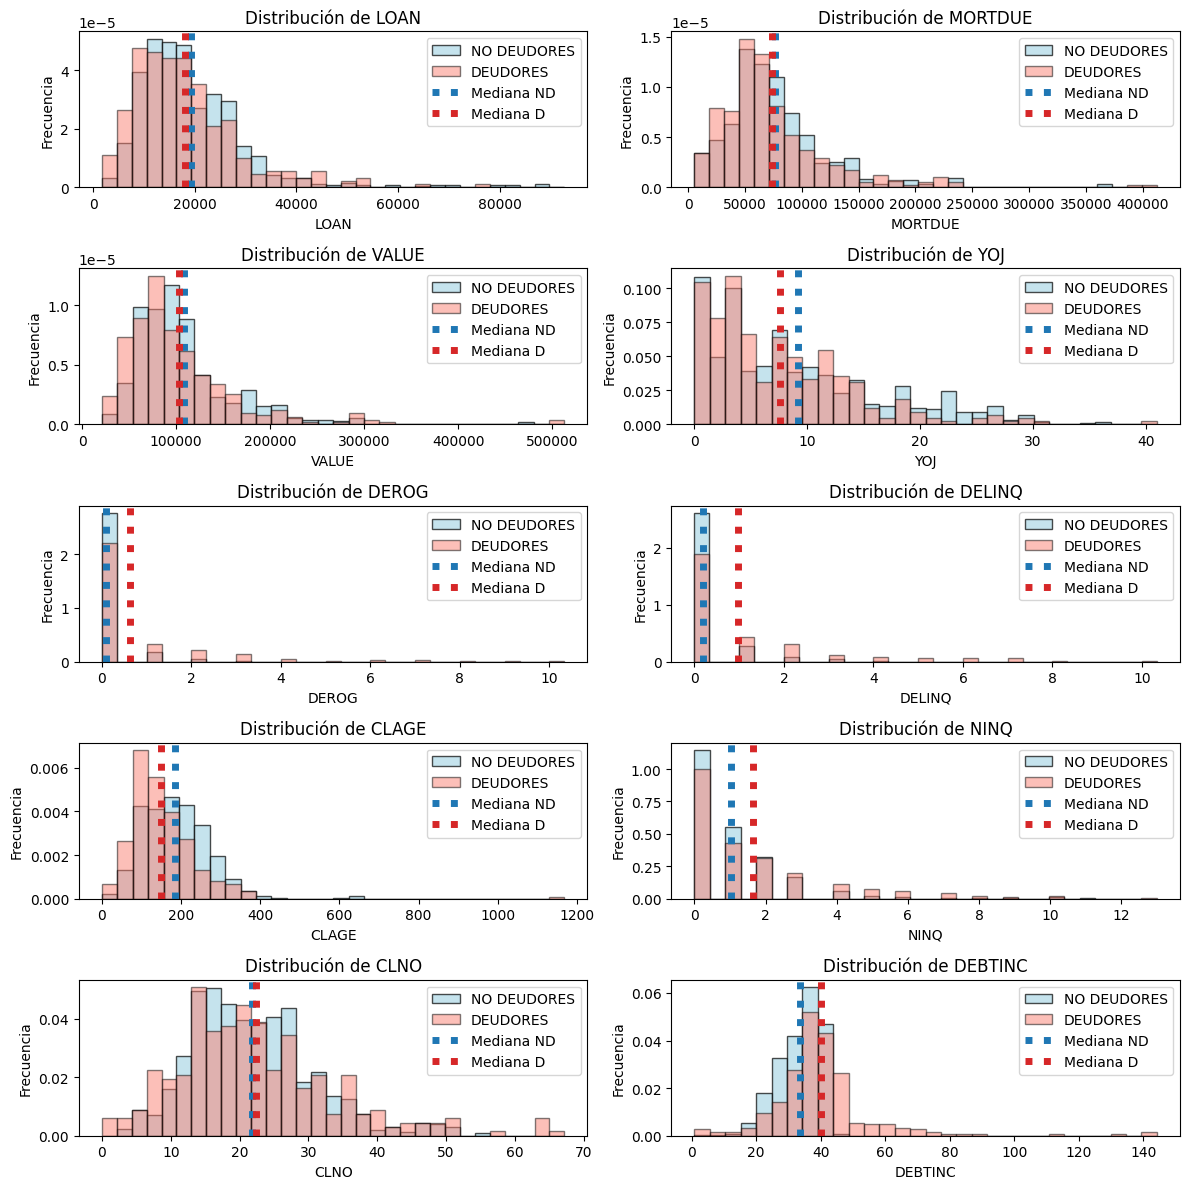

In [3]:
# Suponiendo que el DataFrame es 'dataset' y la columna objetivo es 'TARGET'
# Ejemplo: comparar la distribución de la variable attribute],' para TARGET=0 y TARGET=1
def bins(df0,df1,variable,n):
    """
    Esta funcion genera los bins para el histograma
    """
    xmin = np.min((np.min(df0),np.min(df1)))
    xmax = np.max((np.max(df0),np.max(df1)))
    bin_width = (xmax-xmin)/n
    bins = np.arange(xmin, xmax+bin_width, bin_width)
    return bins

attributes = dataset.columns[1:]  # Excluyendo 'TARGET' y 'ID'
print("Atributos a analizar:", attributes)
fig, axes = plt.subplots(5, 2, figsize=(12, 12))
axes = axes.flatten()

for idx, attribute in enumerate(attributes):
    ax = axes[idx]
    data_0 = dataset[dataset['TARGET'] == 0][attribute]
    data_1 = dataset[dataset['TARGET'] == 1][attribute]
    bin = bins(data_0,data_1,attribute,30)
    ax.hist(
        data_0,
        bins=bin, alpha=0.7, label='NO DEUDORES', color='lightblue', edgecolor='black', density=True
    )
    ax.hist(
        data_1,
        bins=bin, alpha=0.5, label='DEUDORES', color='salmon', edgecolor='black', density=True
    )
    # Calcular estadísticas
    mean_0, mean_1 = data_0.mean(), data_1.mean()
    median_0, median_1 = data_0.median(), data_1.median()
    mode_0, mode_1 = data_0.mode().iloc[0] if not data_0.mode().empty else np.nan, data_1.mode().iloc[0] if not data_1.mode().empty else np.nan

    # Dibujar líneas de estadísticos
    # ax.axvline(mean_0, color='blue', linestyle='--', linewidth=1, label='Media 0')
    # ax.axvline(mean_1, color='black', linestyle='--', linewidth=1, label='Media 1')
    ax.axvline(mean_0, color='tab:blue', linestyle=':', linewidth=5, label='Mediana ND')
    ax.axvline(mean_1, color='tab:red', linestyle=':', linewidth=5, label='Mediana D')

    # ax.axvline(mode_0, color='blue', linestyle='-.', linewidth=1, label='Moda 0')
    # ax.axvline(mode_1, color='black', linestyle='-.', linewidth=1, label='Moda 1')

    ax.set_xlabel(attribute)
    ax.set_ylabel('Frecuencia')
    ax.set_title(f'Distribución de {attribute}')
    # Solo mostrar una vez cada label en la leyenda
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys())

plt.tight_layout()
plt.show()

**También, graficamos la distribución resultante en los conjuntos de entrenamiento y testeo. Se observa que la clase 1 tiene menor cantidad de muestras. Es necesario tener en cuenta este sobremuestreo en una clase para evitar resultados sesgados en los siguientes ejercicios.**

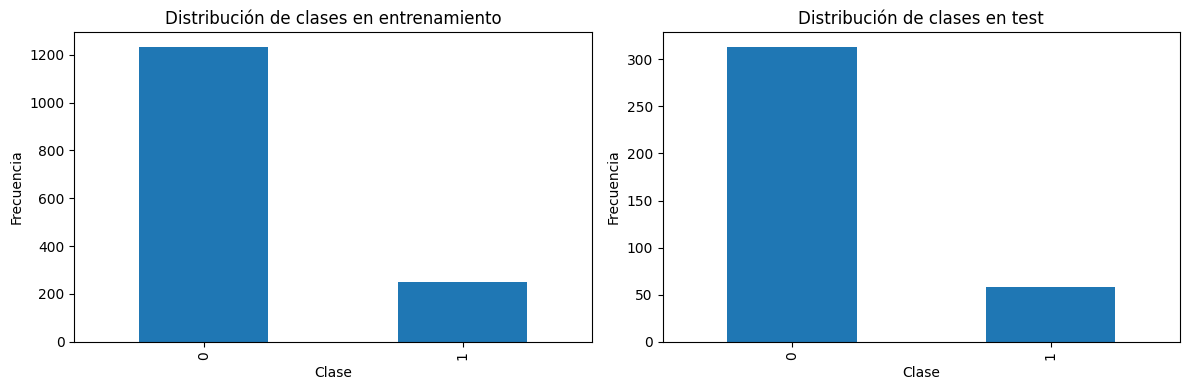

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma de etiquetas (y_train)
pd.Series(y_train).value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set_title("Distribución de clases en entrenamiento")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Frecuencia")

# Histograma de etiquetas (y_test)
pd.Series(y_test).value_counts().sort_index().plot(kind='bar', ax=axes[1])
axes[1].set_title("Distribución de clases en test")
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()


## Ejercicio 2: Predicción con Modelos Lineales

En este ejercicio se entrenarán modelos lineales de clasificación para predecir la variable objetivo.

Para ello, deberán utilizar la clase SGDClassifier de scikit-learn.

Documentación:
- https://scikit-learn.org/stable/modules/sgd.html
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html


**Debido a la distribución desigual previamente mostrada, aplicamos técnica SMOTE para sobremuestrear la clase minoritaria. Se verifica que generamos una distribución con la misma cantidad de muestras de ambas clases.**

In [5]:
# Crear el objeto SMOTE
smote = SMOTE(random_state=42)

# Aplicar solo al entrenamiento
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Antes del SMOTE:", np.bincount(y_train))
print("Después del SMOTE:", np.bincount(y_train_resampled))

Antes del SMOTE: [1232  251]
Después del SMOTE: [1232 1232]


### Ejercicio 2.1: SGDClassifier con hiperparámetros por defecto

Entrenar y evaluar el clasificador SGDClassifier usando los valores por omisión de scikit-learn para todos los parámetros. Únicamente **fijar la semilla aleatoria** para hacer repetible el experimento.

Evaluar sobre el conjunto de **entrenamiento** y sobre el conjunto de **evaluación**, reportando:
- Accuracy
- Precision
- Recall
- F1
- matriz de confusión

In [6]:
# fijamos esta semilla única para reproducibilidad
random_state = 42

In [7]:
# Generamos un clasificador SGD con los parámetros por defecto
clf = SGDClassifier(random_state=random_state)

print("Valores por defecto en SGDClassifier:")
params = clf.get_params()
for param, value in params.items():
    print(f"{param}: {value}")

# Entrenamiento
clf.fit(X_train_resampled, y_train_resampled)

Valores por defecto en SGDClassifier:
alpha: 0.0001
average: False
class_weight: None
early_stopping: False
epsilon: 0.1
eta0: 0.0
fit_intercept: True
l1_ratio: 0.15
learning_rate: optimal
loss: hinge
max_iter: 1000
n_iter_no_change: 5
n_jobs: None
penalty: l2
power_t: 0.5
random_state: 42
shuffle: True
tol: 0.001
validation_fraction: 0.1
verbose: 0
warm_start: False


SGDClassifier(random_state=42)

In [8]:
#Predicción
y_pred = clf.predict(X_test)


**Imprimimos las métricas**

Accuracy: 0.816711590296496
Roc auc: 0.5261650324997246
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.95      0.90       313
           1       0.27      0.10      0.15        58

    accuracy                           0.82       371
   macro avg       0.56      0.53      0.52       371
weighted avg       0.76      0.82      0.78       371



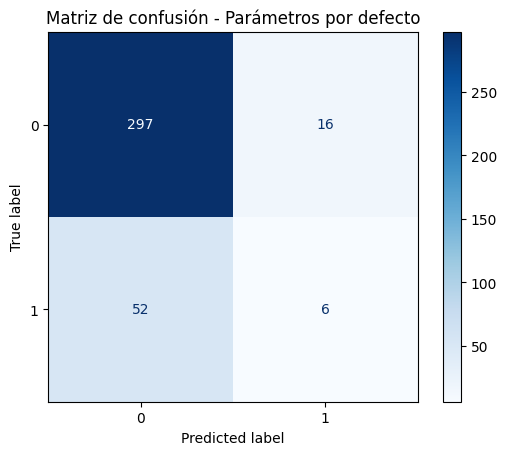

In [9]:
cm = confusion_matrix(y_test, y_pred)

# Precisión simple
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Roc auc:", roc_auc_score(y_test, y_pred))
# Reporte de clasificación completo (precisión, recall, F1)
print("Classification Report:\n", classification_report(y_test, y_pred))

# visualización
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Matriz de confusión - Parámetros por defecto")
plt.show()


**El modelo está fallando en predecir la clase positiva (minoritaria) a pesar de haber sobremuestreado.**

**Accuracy (0.817): El modelo acierta en el 81.7% de los casos totales (pero las clases están desbalanceadas.)**


**En la clase 0 (mayoritaria) hay muy buen desempeño: alta precisión (85%) y recall (95%). Esto significa que el modelo acierta casi siempre cuando predice 0, y además detecta la mayoría de los ceros reales.**

**En la clase 1 (minoritaria) hay un muy mal desempeño: solo detecta el 10% de los verdaderos casos clase 1 (recall = 0.10).  De todas las predicciones positivas, solo el 27% eran realmente positivas (precisión = 0.27). El F1-score de 0.15 es muy bajo, señal de que el modelo prácticamente ignora la clase 1.**


**ROC AUC (0.5262): Indica que dado un dato positivo y otro negativo elegidos al azar, el modelo tiene un 52.62% de probabilidad de asignar correctamente los valores. Si bien la precisión es bastante alta, esta métrica refleja que el clasificador no es mucho mejor que adivinar la clase al azar teniendo un DataSet tan desbalanceado.**

### Ejercicio 2.2: Ajuste de Hiperparámetros

Seleccionar valores para los hiperparámetros principales del SGDClassifier. Como mínimo, probar diferentes funciones de loss, tasas de entrenamiento y tasas de regularización.

Para ello, usar grid-search y 5-fold cross-validation sobre el conjunto de entrenamiento para explorar muchas combinaciones posibles de valores.

Reportar accuracy promedio y varianza para todas las configuraciones.

Para la mejor configuración encontrada, evaluar sobre el conjunto de **entrenamiento** y sobre el conjunto de **evaluación**, reportando:
- Accuracy
- Precision
- Recall
- F1
- matriz de confusión

Documentación:
- https://scikit-learn.org/stable/modules/grid_search.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

**Definimos la grilla de hiperparámetros, optimizaremos sobre:**

- **Función pérdida**:
    - hinge: SVM lineal
    - log_loss: regresión logística

- **Penalty**: Penalización o término de regularización
    - l2: Regularización estándar en SVM
    - l1: Agregan *sparcity* al modelo
    - elasticnet: combina ambas
    
-  **alpha**: Constante multiplicadora de la regularización, directamente proporcional a la misma.
  
- **learning_rate**: tipo de tasa de aprendizaje (eta).
    - constante (eta = eta0)
    - óptima: Opción por defecto. Se toma eta = 1.0 / (alpha * (t + t0)) donde t0 se elige usando un mecanismo propuesto por Leon Bottou.
    - adaptativa: eta constante e igual a eta0 si el entrenamiento continua mejorando, si no hay cambios en episodios consecutivos se divide en 5.

- **eta0**: valor utilizado en learning rate constante y adaptativo.

In [10]:
#Defino grilla de hiperparámetros

param_grid = {
    'loss': ['hinge', 'log_loss'],
    'penalty': ['l2', 'l1', 'elasticnet'], # tipo de penalización
    'alpha': [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1], # tasa de regularización
    'learning_rate': ['constant', 'optimal', 'adaptive'],
    'eta0': [0.001, 0.005, 0.01, 0.05, 0.1], # tasa de aprendizaje
}


**En cada etapa del proceso de validación, buscamos que las cantidades de datos de ambas clases sean comparables. Por eso, al dividir el conjunto de entrenamiento en 5 folds, escaleamos y sobremuestreamos la clase minoritaria para cada uno usando SMOTE. Luego, usamos SGDClassifier para modelar y predecir.**

In [11]:
grid = ParameterGrid(param_grid)

# Dividimos en 5 folds
kf = KFold(n_splits=5, shuffle=True, random_state=random_state)

# Guardar resultados
results = []

for params in grid:

    accuracies = []

    for train_idx, val_idx in kf.split(X):
        # Separar folds
        X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
        y_train_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]

        # Escalar
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_fold)
        X_val_scaled = scaler.transform(X_val_fold)

        # Aplicar SMOTE al set de entrenamiento para sobremuestrear la clase minoritaria
        smote = SMOTE(random_state=42)
        X_resampled, y_resampled = smote.fit_resample(X_train_scaled, y_train_fold)

        # Entrenar modelo con hiperparámetros actuales
        clf = SGDClassifier(**params, random_state=42)
        clf.fit(X_resampled, y_resampled)

        # Predecir y evaluar accuracy
        y_pred = clf.predict(X_val_scaled)
        acc = accuracy_score(y_val_fold, y_pred)
        accuracies.append(acc)

    # Guardar promedio y varianza
    avg_acc = np.mean(accuracies)
    var_acc = np.var(accuracies)

    results.append({
        'params': params,
        'avg_accuracy': avg_acc,
        'var_accuracy': var_acc
    })

**Se muestran de mayor a menor accuracy promedio: accuracies y varianzas**

In [12]:
# Mostrar resultados ordenados por accuracy promedio
sorted_results = sorted(results, key=lambda r: r['avg_accuracy'], reverse=True)

print("Combinaciones por accuracy promedio:")
for res in sorted_results:
    print(f"Accuracy: {res['avg_accuracy']:.4f} | Varianza: {res['var_accuracy']:.6f} | Params: {res['params']}")

Combinaciones por accuracy promedio:
Accuracy: 0.8560 | Varianza: 0.000263 | Params: {'alpha': 0.1, 'eta0': 0.005, 'learning_rate': 'constant', 'loss': 'hinge', 'penalty': 'l1'}
Accuracy: 0.8479 | Varianza: 0.000667 | Params: {'alpha': 0.1, 'eta0': 0.01, 'learning_rate': 'adaptive', 'loss': 'hinge', 'penalty': 'l1'}
Accuracy: 0.8473 | Varianza: 0.000655 | Params: {'alpha': 0.1, 'eta0': 0.05, 'learning_rate': 'adaptive', 'loss': 'hinge', 'penalty': 'l1'}
Accuracy: 0.8468 | Varianza: 0.000640 | Params: {'alpha': 0.1, 'eta0': 0.005, 'learning_rate': 'adaptive', 'loss': 'hinge', 'penalty': 'l1'}
Accuracy: 0.8463 | Varianza: 0.000615 | Params: {'alpha': 0.1, 'eta0': 0.001, 'learning_rate': 'adaptive', 'loss': 'hinge', 'penalty': 'l1'}
Accuracy: 0.8462 | Varianza: 0.000765 | Params: {'alpha': 0.1, 'eta0': 0.001, 'learning_rate': 'optimal', 'loss': 'hinge', 'penalty': 'l1'}
Accuracy: 0.8462 | Varianza: 0.000765 | Params: {'alpha': 0.1, 'eta0': 0.005, 'learning_rate': 'optimal', 'loss': 'hinge

**Elegimos la mejor configuración de hiperparámetros:**

In [13]:
#Mejor configuración:
best_params = sorted_results[0]['params']
print("Mejor configuración encontrada:", best_params)

Mejor configuración encontrada: {'alpha': 0.1, 'eta0': 0.005, 'learning_rate': 'constant', 'loss': 'hinge', 'penalty': 'l1'}


**Escalamos, sobremuestreamos y volvemos a entrenar:**

In [14]:
# Escalar todo el conjunto (entrenamiento completo)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Aplicar SMOTE solo al entrenamiento
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train_scaled, y_train)

# Entrenar modelo final
clf = SGDClassifier(**best_params, random_state=42)
clf.fit(X_resampled, y_resampled)


SGDClassifier(alpha=0.1, eta0=0.005, learning_rate='constant', penalty='l1',
              random_state=42)

**Los mejores parámetros resultan ser la loss de hinge, la penalización l1 con fuerza alpha=0.1 y una tasa de aprendizaje constante e igual a 0.005. Con estos parámetros óptimos, predecimos y calculamos las métricas sobre el conjunto de testeo.**

Accuracy: 0.8410
Precision: 0.4930
Recall: 0.6034
F1-score: 0.5426
Roc auc: 0.7442161507105872
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.88      0.90       313
           1       0.49      0.60      0.54        58

    accuracy                           0.84       371
   macro avg       0.71      0.74      0.72       371
weighted avg       0.86      0.84      0.85       371



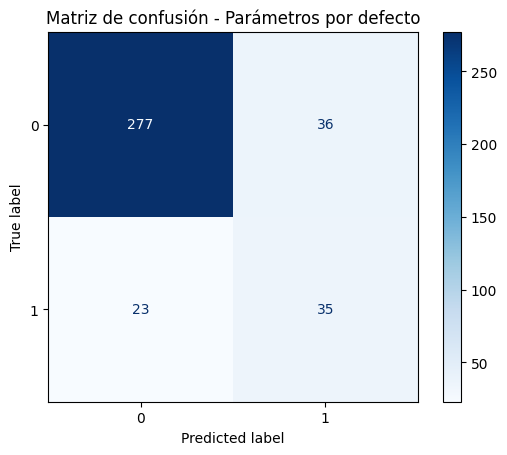

In [15]:
# Predicciones
y_pred = clf.predict(X_test_scaled)

# Métricas
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='binary')
rec = recall_score(y_test, y_pred, average='binary')
f1 = f1_score(y_test, y_pred, average='binary')
cm = confusion_matrix(y_test, y_pred)

# Mostrar métricas
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print("Roc auc:", roc_auc_score(y_test, y_pred))
# Reporte de clasificación completo (precisión, recall, F1)
print("Classification Report:\n", classification_report(y_test, y_pred))

# visualización
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Matriz de confusión - Parámetros por defecto")
plt.show()

**El modelo predice correctamente el 84.1 % de los casos. Sin embargo, a pesar del reescaleo y sobremuestreo usando SMOTE, las clasificaciones de la clase minoritaria siguen siendo incorrectas en muchos casos. De todas las veces que el modelo predijo clase 1, acertó solo el 49 % (precision). Por otro lado, logró identificar el 60 % de los casos reales de clase 1 (recall). Es decir, hay una gran cantidad de falsos positivos, pero es posible capturar más de la mitad de los positivos reales.**

**El ROC AUC de 75 % indica que el modelo distingue entre ambas clases mejor que elegir al azar. De todas formas, el desempeño para detectar la clase 1 (deudores) continúa siendo poco confiable.**



## Ejercicio 3: Árboles de Decisión

En este ejercicio se entrenarán árboles de decisión para predecir la variable objetivo.

Para ello, deberán utilizar la clase DecisionTreeClassifier de scikit-learn.

Documentación:
- https://scikit-learn.org/stable/modules/tree.html
  - https://scikit-learn.org/stable/modules/tree.html#tips-on-practical-use
- https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- https://scikit-learn.org/stable/auto_examples/tree/plot_unveil_tree_structure.html

### Ejercicio 3.1: DecisionTreeClassifier con hiperparámetros por defecto

Entrenar y evaluar el clasificador DecisionTreeClassifier usando los valores por omisión de scikit-learn para todos los parámetros. Únicamente **fijar la semilla aleatoria** para hacer repetible el experimento.

Evaluar sobre el conjunto de **entrenamiento** y sobre el conjunto de **evaluación**, reportando:
- Accuracy
- Precision
- Recall
- F1
- matriz de confusión


**Repetiremos la clasificación utilizando árboles de decisión. En primer lugar, ajustamos un árbol de decisión a los datos con los parámetros por defecto:**

In [16]:
# Generamos un clasificador de árboles de decisión con los parámetros por defecto
clf = DecisionTreeClassifier(random_state=random_state)

print("Valores por defecto en DecisionTreeClassifier:")
params = clf.get_params()
for param, value in params.items():
    print(f"{param}: {value}")


clf.fit(X_train, y_train)


Valores por defecto en DecisionTreeClassifier:
ccp_alpha: 0.0
class_weight: None
criterion: gini
max_depth: None
max_features: None
max_leaf_nodes: None
min_impurity_decrease: 0.0
min_samples_leaf: 1
min_samples_split: 2
min_weight_fraction_leaf: 0.0
monotonic_cst: None
random_state: 42
splitter: best


DecisionTreeClassifier(random_state=42)

**Predecimos:**

In [17]:
y_train_pred = clf.predict(X_train)
y_test_pred = clf.predict(X_test)

**Calculamos las métricas:**

In [18]:
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
print(f'Train accuracy: {train_acc:0.2}')
print(f'Test accuracy: {test_acc:0.2}')


Train accuracy: 1.0
Test accuracy: 0.89


Evaluación sobre el conjunto de ENTRENAMIENTO:
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000
Roc auc: 1.0


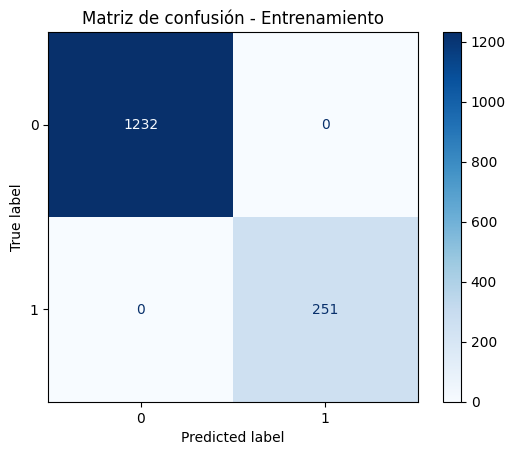

Evaluación sobre el conjunto de EVALUACIÓN (Test):
Accuracy:  0.8868
Precision: 0.6429
Recall:    0.6207
F1-score:  0.6316
Roc auc: 0.7783959457970695


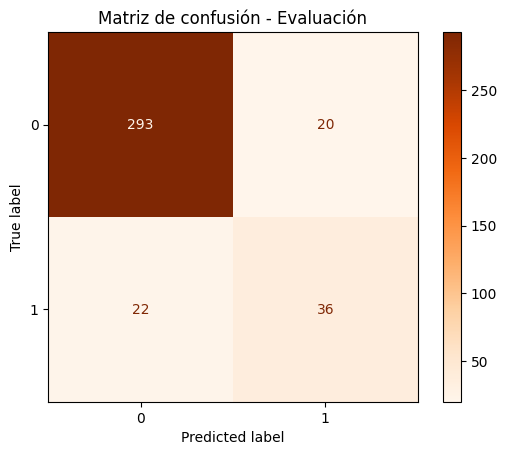

In [19]:
# MÉTRICAS SOBRE ENTRENAMIENTO
print("Evaluación sobre el conjunto de ENTRENAMIENTO:")
print(f"Accuracy:  {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Precision: {precision_score(y_train, y_train_pred):.4f}")
print(f"Recall:    {recall_score(y_train, y_train_pred):.4f}")
print(f"F1-score:  {f1_score(y_train, y_train_pred):.4f}")
print("Roc auc:", roc_auc_score(y_train, y_train_pred))

cm_train = confusion_matrix(y_train, y_train_pred)
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train)
disp_train.plot(cmap='Blues')
plt.title("Matriz de confusión - Entrenamiento")
plt.show()

# MÉTRICAS SOBRE TEST/EVALUACIÓN
print("Evaluación sobre el conjunto de EVALUACIÓN (Test):")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_test_pred):.4f}")
print("Roc auc:", roc_auc_score(y_test, y_test_pred))

cm_test = confusion_matrix(y_test, y_test_pred)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot(cmap='Oranges')
plt.title("Matriz de confusión - Evaluación")
plt.show()


**En el conjunto de entrenamiento, las métricas dan muy bien (exactitud y precisión del 100%). Sin embargo, cuando las medimos en el conjunto de evaluación, todas disminuyen. En particular hay una fuerte bajada de precisión, lo que significa que el modelo comete más falsos positivos en test. Eso quiere decir que el modelo está sobreajustado: aprendió demasiado bien los datos de entrenamiento, pero pierde rendimiento con datos nuevos.**

### Ejercicio 3.2: Ajuste de Hiperparámetros

Seleccionar valores para los hiperparámetros principales del DecisionTreeClassifier. Como mínimo, probar diferentes criterios de partición (criterion), profundidad máxima del árbol (max_depth), y cantidad mínima de samples por hoja (min_samples_leaf).

Para ello, usar grid-search y 5-fold cross-validation sobre el conjunto de entrenamiento para explorar muchas combinaciones posibles de valores.

Reportar accuracy promedio y varianza para todas las configuraciones.

Para la mejor configuración encontrada, evaluar sobre el conjunto de **entrenamiento** y sobre el conjunto de **evaluación**, reportando:
- Accuracy
- Precision
- Recall
- F1
- matriz de confusión


Documentación:
- https://scikit-learn.org/stable/modules/grid_search.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

**Definimos la grilla de hiperparámetros. En este caso, optimizaremos sobre:**
- **max_depth:** Profundidad máxima del árbol.
- **min_samples_leaf**: Número mínimo de muestras necesarias para que se considere una hoja del árbol
- **min_samples_split**: Número mínimo de muestras para dividir un nodo

- **criterion**:
    - gini: impureza de gini
    - log_loss: regresión logística
    - entropy: información de Shannon
- **splitter**: estrategia usada para dividir en cada nodo

In [20]:
param_grid = {
    'max_depth': [2, 3, 4, 5, 10, 20, 40, 100, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4, 10],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'splitter': ['best', 'random']
}


**Realizamos la búsqueda de los mejores híper-parámetros optimizando sobre la accuracy.**

In [21]:
# Configuramos la búsqueda de hiperparámetros
clf = DecisionTreeClassifier(random_state=random_state)

grid_search = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    scoring='accuracy',     # o 'accuracy', 'recall', etc. según tu objetivo
    cv=5,                   # 5-fold cross-validation
    n_jobs=-1,              # Usa todos los núcleos disponibles
    verbose=0
)

# Realizamos la validación cruzada sobre los datos de entrenamiento
# ajustando de acuerdo a la mejor accuracy

grid_search.fit(X_train, y_train)

# Convertimos los resultados a un DataFrame
cv_results = pd.DataFrame(grid_search.cv_results_)

In [22]:
# Seleccionamos solo las columnas importantes
summary = cv_results[[
    'params',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]]

# Renombramos columnas para claridad
summary = summary.rename(columns={
    'mean_test_score': 'avg_score',
    'std_test_score': 'std_score'
})

# Ordenamos por mejor puntaje
summary = summary.sort_values(by='avg_score', ascending=False)
print("Combinaciones por promedio de score:")
print(summary)

Combinaciones por promedio de score:
                                                params  avg_score  std_score  \
526  {'criterion': 'log_loss', 'max_depth': 5, 'min...   0.883340   0.003580   
522  {'criterion': 'log_loss', 'max_depth': 5, 'min...   0.883340   0.003580   
524  {'criterion': 'log_loss', 'max_depth': 5, 'min...   0.883340   0.003580   
310  {'criterion': 'entropy', 'max_depth': 5, 'min_...   0.883340   0.003580   
306  {'criterion': 'entropy', 'max_depth': 5, 'min_...   0.883340   0.003580   
..                                                 ...        ...        ...   
259  {'criterion': 'entropy', 'max_depth': 3, 'min_...   0.842879   0.009789   
45   {'criterion': 'gini', 'max_depth': 3, 'min_sam...   0.842879   0.009789   
43   {'criterion': 'gini', 'max_depth': 3, 'min_sam...   0.842879   0.009789   
263  {'criterion': 'entropy', 'max_depth': 3, 'min_...   0.842879   0.009789   
47   {'criterion': 'gini', 'max_depth': 3, 'min_sam...   0.842879   0.009789   

  

**Mejor configuración:**

In [23]:
print("Mejores hiperparámetros encontrados:")
print(grid_search.best_params_)

print(f"Mejor accuracy: {grid_search.best_score_:.4f}")


Mejores hiperparámetros encontrados:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2, 'splitter': 'best'}
Mejor accuracy: 0.8833


**Evaluamos en el conjunto de evaluación para la mejor configuración lograda:**

Accuracy: 0.8976
Precision: 0.8571
Recall: 0.4138
F1-score: 0.5581
Roc auc: 0.7005067753663105
Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.99      0.94       313
           1       0.86      0.41      0.56        58

    accuracy                           0.90       371
   macro avg       0.88      0.70      0.75       371
weighted avg       0.89      0.90      0.88       371



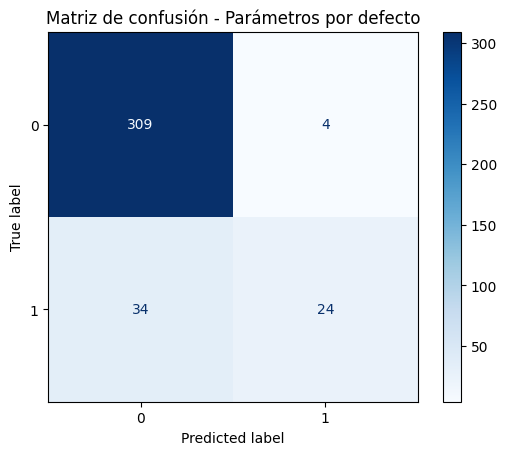

In [24]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Métricas
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='binary')
rec = recall_score(y_test, y_pred, average='binary')
f1 = f1_score(y_test, y_pred, average='binary')
cm = confusion_matrix(y_test, y_pred)

# Mostrar métricas
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print("Roc auc:", roc_auc_score(y_test, y_pred))
# Reporte de clasificación completo (precisión, recall, F1)
print("Classification Report:\n", classification_report(y_test, y_pred))

# visualización
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Matriz de confusión - Parámetros por defecto")
plt.show()


**Se puede ver que el modelo presenta una buena precisión (89.8%) y una alta precisión para la clase 1 (85.7%). Sin embargo, el recall es bajo lo que indica que existen muchos casos de la clase 1 (deudores) que quedan sin capturar. En este caso, sería necesario reducir la aparición de falsos negativos. Repetimos el experimento, aplicando el mismo reescaleo que se utilizó anteriormente.**

In [25]:
grid = ParameterGrid(param_grid)

# Dividimos en 5 folds
kf = KFold(n_splits=5, shuffle=True, random_state=random_state)

# Guardar resultados
results = []

for params in grid:

    accuracies = []
    precisions = []
    recalls = []
    f1_scores = []

    for train_idx, val_idx in kf.split(X):
        # Separar folds
        X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
        y_train_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]

        # Escalar
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_fold)
        X_val_scaled = scaler.transform(X_val_fold)

        # Aplicar SMOTE al set de entrenamiento para sobremuestrear la clase minoritaria
        smote = SMOTE(random_state=42)
        X_resampled, y_resampled = smote.fit_resample(X_train_scaled, y_train_fold)

        # Entrenar modelo con hiperparámetros actuales
        clf = DecisionTreeClassifier(**params, random_state=42, class_weight='balanced')
        clf.fit(X_resampled, y_resampled)

        # Predecir y evaluar accuracy
        y_pred = clf.predict(X_val_scaled)
        acc = accuracy_score(y_val_fold, y_pred)
        prec = precision_score(y_val_fold, y_pred, average='binary')
        rec = recall_score(y_val_fold, y_pred, average='binary')
        f1 = f1_score(y_val_fold, y_pred, average='binary')
        cm = confusion_matrix(y_val_fold, y_pred)

        accuracies.append(acc)
        precisions.append(prec)
        recalls.append(rec)
        f1_scores.append(f1)


    # Guardar promedio y varianza
    avg_acc = np.mean(accuracies)
    var_acc = np.var(accuracies)
    avg_prec = np.mean(precisions)
    var_prec = np.var(precisions)
    avg_rec = np.mean(recalls)
    var_rec = np.var(recalls)
    avg_f1 = np.mean(f1_scores)
    var_f1 = np.var(f1_scores)

    results.append({
        'params': params,
        'avg_accuracy': avg_acc,
        'var_accuracy': var_acc,
        'avg_precision': avg_prec,
        'var_precision': var_prec,
        'avg_recall': avg_rec,
        'var_recall': var_rec,
        'avg_f1': avg_f1,
        'var_f1': var_f1
    })

**Mostramos los resultados ordenados por accuracy promedio**

In [26]:
# Mostrar resultados ordenados por accuracy promedio
sorted_results = sorted(results, key=lambda r: r['avg_accuracy'], reverse=True)

print("Combinaciones por accuracy promedio:")
for res in sorted_results:
    print(f"accuracy: {res['avg_accuracy']:.4f} | Varianza: {res['var_accuracy']:.6f} | Params: {res['params']}")

Combinaciones por accuracy promedio:
accuracy: 0.8711 | Varianza: 0.000439 | Params: {'criterion': 'entropy', 'max_depth': 40, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
accuracy: 0.8711 | Varianza: 0.000439 | Params: {'criterion': 'entropy', 'max_depth': 100, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
accuracy: 0.8711 | Varianza: 0.000439 | Params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
accuracy: 0.8711 | Varianza: 0.000439 | Params: {'criterion': 'log_loss', 'max_depth': 40, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
accuracy: 0.8711 | Varianza: 0.000439 | Params: {'criterion': 'log_loss', 'max_depth': 100, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
accuracy: 0.8711 | Varianza: 0.000439 | Params: {'criterion': 'log_loss', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}


**Accedemos a la mejor configuración para la versión reescaleada**

In [27]:
#Mejor configuración:
best_params = sorted_results[0]['params']
print("Mejor configuración encontrada:", best_params)

Mejor configuración encontrada: {'criterion': 'entropy', 'max_depth': 40, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}


**Entrenamos con estos parámetros**

In [28]:
# Escalar todo el conjunto (entrenamiento completo)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Aplicar SMOTE solo al entrenamiento
smote = SMOTE(random_state=random_state)
X_resampled, y_resampled = smote.fit_resample(X_train_scaled, y_train)

# Entrenar modelo final
clf = DecisionTreeClassifier(**best_params, random_state=random_state)
clf.fit(X_resampled, y_resampled)


DecisionTreeClassifier(criterion='entropy', max_depth=40, random_state=42,
                       splitter='random')

**Evaluamos sobre el conjunto de testeo**

Accuracy: 0.8356
Precision: 0.4810
Recall: 0.6552
F1-score: 0.5547
Roc auc: 0.7620909992288201
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.87      0.90       313
           1       0.48      0.66      0.55        58

    accuracy                           0.84       371
   macro avg       0.71      0.76      0.73       371
weighted avg       0.86      0.84      0.85       371



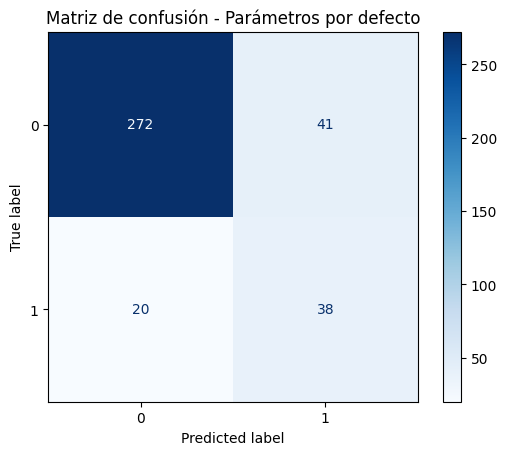

In [29]:
y_pred = clf.predict(X_test_scaled)


# Métricas
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='binary')
rec = recall_score(y_test, y_pred, average='binary')
f1 = f1_score(y_test, y_pred, average='binary')
cm = confusion_matrix(y_test, y_pred)

# Mostrar métricas
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print("Roc auc:", roc_auc_score(y_test, y_pred))
# Reporte de clasificación completo (precisión, recall, F1)
print("Classification Report:\n", classification_report(y_test, y_pred))

# visualización
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Matriz de confusión - Parámetros por defecto")
plt.show()

**Podemos ver que en este segundo caso, el recall aumenta pero la disminuye fuertemente la precisión en la clase minoritaria. Esto quiere decir que el segundo modelo detecta más positivos con menor precisión. La decisión de cuál modelo es más conveniente depende del tipo de política que se quiera aplicar, es decir, si un prestamista está menos dispuesto a arriesgarse debería usar el segundo modelo que tiene menos falsos negativos pero una menor precisión en la detección de positivos reales. Esto se debe a que al equilibrar la clase minoritaria usando SMOTE generamos datos sintéticos que dan más importancia a esta clase y por lo tanto los casos pertenecientes a la misma se detectan mejor pero al no ser datos *reales* el modelo pierde precisión.**